# Pipeline GPU n°1 — PyTorch → ONNX → TensorRT → CUDA/cuDNN → GPU

**TP Déploiement IA — analyse comparative de pipelines de déploiement (CPU / GPU)**

| Couche | Dans ce notebook |
|---|---|
| Haut niveau | PyTorch — ResNet-18 pré-entraîné ImageNet |
| Format du modèle | ONNX (graphe statique, batch de 10) |
| Middle level | TensorRT : fusion de couches, sélection de tactiques (kernels), FP16 optionnel |
| Bas niveau | CUDA, cuDNN / cuBLAS et kernels TensorRT (Tensor Cores en FP16) |
| Matériel | GPU Google Colab (NVIDIA T4) |

**Environnement Colab : GPU T4** (*Exécution > Modifier le type d'exécution*), puis *Exécution > Tout exécuter*.

**Variantes mesurées dans ce notebook**
- `pytorch_eager` — PyTorch eager FP32 (référence, même GPU)
- `tensorrt_fp32` — **pipeline étudié** : moteur TensorRT FP32 (comparaison à précision égale avec les autres pipelines)
- `tensorrt_fp16` — moteur TensorRT autorisé en FP16 (Tensor Cores)

## 0. Installation

La version de TensorRT est choisie selon la version de CUDA de PyTorch ; `nvidia-ml-py` donne accès aux capteurs du GPU (NVML).

In [1]:
import subprocess, sys
import torch

cuda_major = (torch.version.cuda or "12").split(".")[0]
for trt_pkg in (f"tensorrt-cu{cuda_major}", "tensorrt"):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", trt_pkg, "onnx", "onnxscript", "nvidia-ml-py"])
    if r.returncode == 0:
        print("installé :", trt_pkg)
        break
!nvidia-smi --query-gpu=name,driver_version,power.limit,clocks.max.sm --format=csv

installé : tensorrt-cu13
name, driver_version, power.limit [W], clocks.max.sm [MHz]
Tesla T4, 580.82.07, 70.00 W, 1590 MHz


In [2]:
# Identifiant du pipeline (seule cellule de configuration propre à ce notebook)
PIPELINE_ID = "gpu1_tensorrt"
PIPELINE_LABEL = "GPU 1 · PyTorch → ONNX → TensorRT"
PLATFORM = "GPU"
PIPELINE_LAYERS = {
    "haut_niveau": "PyTorch",
    "format": "ONNX",
    "middle_level": "TensorRT",
    "bas_niveau": "CUDA / cuDNN / cuBLAS",
    "materiel": "GPU Google Colab",
}

## 1. Protocole expérimental commun

Les cellules « COMMUNE » ci-dessous sont **strictement identiques dans les 4 notebooks** : mêmes données, même prétraitement, même modèle, même méthode de mesure.

| Élément | Choix |
|---|---|
| Données | 50 images du jeu de test CIFAR-10 : les 5 premières de chaque classe (sous-ensemble équilibré et déterministe ; indices et empreintes SHA-256 enregistrés) |
| Prétraitement | 32×32 → 224×224 (bilinéaire), puis normalisation ImageNet (moyenne 0,485 / 0,456 / 0,406 ; écart-type 0,229 / 0,224 / 0,225) |
| Modèle | ResNet-18 torchvision, poids `IMAGENET1K_V1`, sans réentraînement |
| Top-1 sur 10 classes | les 1000 classes ImageNet sont regroupées en 10 super-classes CIFAR-10 (somme des probabilités softmax), prédiction = argmax des 10 scores |
| Performances | batch de 10 (5 batchs), 10 batchs de chauffe, puis **10 exécutions** chronométrées du passage complet ; chaque batch est chronométré avec synchronisation du GPU ; les données sont déjà en mémoire du device |
| Statistiques | moyenne, écart-type, minimum, maximum et coefficient de variation (CV = écart-type / moyenne) |
| Énergie | GPU : NVML (énergie de la carte) ; CPU : Intel RAPL si la VM l'expose (rarement sur Colab) ; fenêtres d'au moins 5 s |
| Référence | chaque notebook mesure aussi **PyTorch eager FP32 sur le même matériel** : accélérations et écarts de prédiction sont calculés dans les mêmes conditions |

In [3]:
# ============ CELLULE COMMUNE 1/6 : imports, paramètres expérimentaux, environnement ============
# (identique dans les 4 notebooks : ne modifier qu'ici, et de la même façon partout)
import os, sys, gc, re, glob, json, time, copy, hashlib, platform, datetime, threading, warnings
from collections import Counter
import numpy as np
import pandas as pd
import torch
import torchvision
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

SEED = 0
IMAGES_PER_CLASS = 5        # 5 images x 10 classes = 50 images (sous-ensemble équilibré et déterministe)
BATCH_SIZE = 10             # même taille de batch pour les 4 pipelines : 50 images = 5 batchs
N_WARMUP = 10               # batchs de chauffe, non chronométrés
N_RUNS = 10                 # exécutions chronométrées du passage complet sur les 50 images (>= 3 exigées)
ENERGY_WINDOW_S = 5.0       # durée minimale d'une fenêtre de mesure énergétique (résolution des capteurs)
N_ENERGY_RUNS = 3           # répétitions de la mesure énergétique
IDLE_WINDOW_S = 2.0         # mesure de la puissance au repos (avant chaque série)
IMG_SIZE = 224
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
RESULTS_DIR, FIGURES_DIR = "results", "figures"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = "cuda" if PLATFORM == "GPU" else "cpu"
if DEVICE == "cuda":
    assert torch.cuda.is_available(), "Aucun GPU détecté : Exécution > Modifier le type d'exécution > GPU (T4)."
    torch.backends.cudnn.benchmark = True   # formes fixes : cuDNN choisit son meilleur algorithme une fois pour toutes
else:
    torch.set_num_threads(os.cpu_count())
    if torch.cuda.is_available():
        print("⚠️ Un GPU est visible : pour des conditions comparables, exécuter ce notebook sur un environnement CPU.")
N_THREADS = torch.get_num_threads()


def get_env_info():
    """Décrit la machine et les versions logicielles (enregistré avec les résultats)."""
    info = {
        "date_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
        "python": platform.python_version(), "os": platform.platform(),
        "cpu_count": os.cpu_count(), "torch_threads": N_THREADS,
        "torch": torch.__version__, "torchvision": torchvision.__version__,
    }
    try:
        lines = open("/proc/cpuinfo").read().splitlines()
        info["cpu_model"] = next(l.split(":", 1)[1].strip() for l in lines if l.startswith("model name"))
        flags = next(l.split(":", 1)[1].split() for l in lines if l.startswith("flags"))
        info["cpu_isa"] = [f for f in ("avx2", "avx512f", "avx512_vnni", "avx512_bf16", "amx_bf16") if f in flags]
    except Exception:
        info["cpu_model"] = platform.processor()
    try:
        info["ram_gb"] = round(int(open("/proc/meminfo").readline().split()[1]) / 1024**2, 1)
    except Exception:
        pass
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        info.update(gpu=p.name, gpu_mem_gb=round(p.total_memory / 1024**3, 1),
                    gpu_compute_capability=f"{p.major}.{p.minor}",
                    cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version())
    for mod in ("onnx", "onnxruntime", "openvino", "tensorrt"):
        try:
            info[mod] = __import__(mod).__version__
        except Exception:
            pass
    return info


for k, v in get_env_info().items():
    print(f"{k:>24} : {v}")

                date_utc : 2026-11-20T17:02:46+00:00
                  python : 3.13.16
                      os : Linux-6.6.159+-x86_64-with-glibc2.39
               cpu_count : 2
           torch_threads : 1
                   torch : 2.14.1+cu130
             torchvision : 0.29.1+cu130
               cpu_model : Intel(R) Xeon(R) CPU @ 2.00GHz
                 cpu_isa : ['avx2', 'avx512f']
                  ram_gb : 12.7
                     gpu : Tesla T4
              gpu_mem_gb : 14.6
  gpu_compute_capability : 7.5
                    cuda : 13.0
                   cudnn : 92800
                    onnx : 1.23.2
                tensorrt : 11.5.0.63


In [4]:
# ============ CELLULE COMMUNE 2/6 : données (50 images CIFAR-10) et prétraitement ============
CIFAR10_CLASSES = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True)
targets = np.asarray(testset.targets)
# Sous-ensemble déterministe : les 5 premières images de chaque classe dans l'ordre du jeu de test
SUBSET_INDICES = sorted(int(i) for c in range(10) for i in np.flatnonzero(targets == c)[:IMAGES_PER_CLASS])
images_pil = [testset[i][0] for i in SUBSET_INDICES]          # images PIL 32x32
LABELS = targets[SUBSET_INDICES]
N_IMAGES = len(SUBSET_INDICES)
assert N_IMAGES == 50 and N_IMAGES % BATCH_SIZE == 0

# Prétraitement aligné sur le pré-entraînement ImageNet de ResNet-18 :
# redimensionnement 32x32 -> 224x224 (bilinéaire) puis normalisation avec la moyenne / l'écart-type ImageNet.
# (Pas de Resize(256)+CenterCrop(224) : sur une image 32x32 agrandie, le recadrage couperait l'objet.)
preprocess = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.BILINEAR, antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
X_ALL = torch.stack([preprocess(im) for im in images_pil]).contiguous()     # (50, 3, 224, 224) float32
CPU_BATCHES = [b.contiguous() for b in torch.split(X_ALL, BATCH_SIZE)]      # 5 batchs de 10, pré-chargés en mémoire

# Empreintes : permettent de vérifier que les 4 notebooks ont traité EXACTEMENT les mêmes entrées
RAW_SHA = hashlib.sha256(np.stack([np.asarray(im) for im in images_pil]).tobytes()).hexdigest()[:16]
INPUT_SHA = hashlib.sha256(X_ALL.numpy().tobytes()).hexdigest()[:16]
print(f"{N_IMAGES} images | répartition : {np.bincount(LABELS, minlength=10).tolist()} | tenseur {tuple(X_ALL.shape)}")
print(f"empreinte images brutes : {RAW_SHA} | empreinte tenseur prétraité : {INPUT_SHA}")

100%|██████████| 170M/170M [25:39<00:00, 111kB/s]


50 images | répartition : [5, 5, 5, 5, 5, 5, 5, 5, 5, 5] | tenseur (50, 3, 224, 224)
empreinte images brutes : ac22f720f545b224 | empreinte tenseur prétraité : b581e1365a579ac5


In [5]:
# ============ CELLULE COMMUNE 3/6 : modèle ResNet-18 ImageNet et évaluation sur 10 classes ============
WEIGHTS = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=WEIGHTS).eval()
IMAGENET_CATEGORIES = WEIGHTS.meta["categories"]
WEIGHTS_SHA = hashlib.sha256(b"".join(t.detach().cpu().numpy().tobytes()
                                      for t in model.state_dict().values())).hexdigest()[:16]
print(f"ResNet-18 ({WEIGHTS.name}) : {sum(p.numel() for p in model.parameters())/1e6:.1f} M paramètres | empreinte poids : {WEIGHTS_SHA}")

# Le modèle pré-entraîné produit 1000 logits ImageNet. Pour mesurer une précision Top-1 sur les
# 10 classes CIFAR-10 SANS réentraîner (le modèle reste identique dans les 4 pipelines), on regroupe
# les classes ImageNet correspondant à chaque classe CIFAR-10 : score(c) = somme des probabilités
# softmax des classes ImageNet associées à c ; prédiction = argmax des 10 scores.
# Plages (a, b) = familles d'indices ImageNet contiguës ; chaînes = noms de classes ImageNet.
CIFAR_TO_IMAGENET = {
    "airplane":   ["airliner", "warplane", "wing"],
    "automobile": ["sports car", "convertible", "cab", "beach wagon", "jeep", "limousine",
                   "minivan", "Model T", "racer"],
    "bird":       [(7, 24), (80, 100), (127, 146)],
    "cat":        [(281, 285)],                              # tabby ... Egyptian cat (chats domestiques)
    "deer":       ["hartebeest", "impala", "gazelle"],       # ImageNet-1k n'a pas de classe « cerf »
    "dog":        [(151, 268)],                              # Chihuahua ... Mexican hairless
    "frog":       ["bullfrog", "tree frog", "tailed frog"],
    "horse":      ["sorrel", "horse cart"],
    "ship":       ["container ship", "liner", "pirate", "schooner", "submarine", "yawl", "catamaran",
                   "trimaran", "fireboat", "lifeboat", "speedboat", "aircraft carrier", "wreck",
                   "gondola", "canoe"],
    "truck":      ["trailer truck", "fire engine", "garbage truck", "moving van", "tow truck"],
}
_name_to_idx = {n: i for i, n in enumerate(IMAGENET_CATEGORIES)}
CIFAR_GROUPS = []
for c in CIFAR10_CLASSES:
    idx = []
    for spec in CIFAR_TO_IMAGENET[c]:
        idx += list(range(spec[0], spec[1] + 1)) if isinstance(spec, tuple) else [_name_to_idx[spec]]
    CIFAR_GROUPS.append(np.array(sorted(set(idx))))
print("classes ImageNet regroupées par classe CIFAR-10 :", {c: len(g) for c, g in zip(CIFAR10_CLASSES, CIFAR_GROUPS)})


def softmax(z):
    z = z.astype(np.float64) - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def cifar_predictions(logits):
    p = softmax(logits)
    return np.stack([p[:, g].sum(axis=1) for g in CIFAR_GROUPS], axis=1).argmax(axis=1)


def evaluate_logits(logits):
    pred = cifar_predictions(logits)
    correct = pred == LABELS
    return {"top1_accuracy": float(correct.mean()), "n_correct": int(correct.sum()),
            "per_class_accuracy": {c: float(correct[LABELS == k].mean()) for k, c in enumerate(CIFAR10_CLASSES)},
            "cifar_pred": pred.tolist(), "imagenet_top1": logits.argmax(axis=1).tolist()}


def compare_logits(logits, ref):
    """Écart d'une variante à la référence PyTorch eager FP32 (même notebook, même device)."""
    d = np.abs(logits.astype(np.float64) - ref.astype(np.float64))
    return {"max_abs_diff": float(d.max()), "mean_abs_diff": float(d.mean()),
            "imagenet_top1_agreement": float((logits.argmax(1) == ref.argmax(1)).mean()),
            "imagenet_top5_overlap": float(np.mean([len(set(a) & set(b)) / 5 for a, b in
                                                    zip(np.argsort(-logits, 1)[:, :5], np.argsort(-ref, 1)[:, :5])])),
            "cifar_pred_agreement": float((cifar_predictions(logits) == cifar_predictions(ref)).mean())}

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 130MB/s]


ResNet-18 (IMAGENET1K_V1) : 11.7 M paramètres | empreinte poids : 94c3ff0d5591a630
classes ImageNet regroupées par classe CIFAR-10 : {'airplane': 3, 'automobile': 9, 'bird': 59, 'cat': 5, 'deer': 3, 'dog': 118, 'frog': 3, 'horse': 2, 'ship': 15, 'truck': 5}


In [6]:
# ============ CELLULE COMMUNE 4/6 : mesure des performances et de l'énergie ============
def sync():
    """Les appels GPU sont asynchrones : on attend la fin réelle du calcul avant de lire l'horloge."""
    if DEVICE == "cuda":
        torch.cuda.synchronize()


def benchmark(infer_fn, batches, n_warmup=N_WARMUP, n_runs=N_RUNS):
    """Chauffe, puis n_runs passages complets sur les 50 images ; chaque batch est chronométré
    (time.perf_counter + synchronisation). Données déjà en mémoire du device : seul le calcul
    d'inférence est mesuré. Le ramasse-miettes Python est suspendu pendant chaque passage."""
    for i in range(n_warmup):
        infer_fn(batches[i % len(batches)])
    sync()
    runs = []
    for _ in range(n_runs):
        gc.collect()
        gc.disable()
        try:
            lat_ms = []
            for b in batches:
                t0 = time.perf_counter()
                infer_fn(b)
                sync()
                lat_ms.append((time.perf_counter() - t0) * 1e3)
        finally:
            gc.enable()
        total_s = sum(lat_ms) / 1e3
        runs.append({"total_s": total_s,
                     "throughput_img_s": N_IMAGES / total_s,
                     "latency_per_image_ms": total_s * 1e3 / N_IMAGES,
                     "latency_batch_mean_ms": float(np.mean(lat_ms)),
                     "latency_batch_ms": lat_ms})
    return runs


def describe(values):
    """Moyenne, écart-type (non biaisé), min, max et coefficient de variation."""
    v = np.asarray(values, dtype=float)
    std = float(v.std(ddof=1)) if v.size > 1 else 0.0
    mean = float(v.mean())
    return {"mean": mean, "std": std, "min": float(v.min()), "max": float(v.max()),
            "cv_pct": 100 * std / mean if mean else None, "n": int(v.size)}


def summarize_runs(runs):
    out = {k: describe([r[k] for r in runs])
           for k in ("throughput_img_s", "latency_per_image_ms", "latency_batch_mean_ms", "total_s")}
    all_batches = np.concatenate([r["latency_batch_ms"] for r in runs])
    out["latency_batch_p50_ms"] = float(np.percentile(all_batches, 50))
    out["latency_batch_p95_ms"] = float(np.percentile(all_batches, 95))
    return out


class EnergyMeter:
    """Énergie consommée pendant l'exécution d'une fonction.
    GPU : NVML (compteur d'énergie de la carte si disponible, sinon puissance échantillonnée x durée).
    CPU : Intel RAPL (/sys/class/powercap), rarement exposé dans les VM Colab -> mesure alors indisponible.
    Périmètre : carte GPU seule (NVML) ou package CPU entier (RAPL), jamais la machine complète."""

    def __init__(self, device, sample_period_s=0.02):
        self.device, self.period, self.source, self.rapl = device, sample_period_s, None, []
        if device == "cuda":
            try:
                import pynvml
                pynvml.nvmlInit()
                self.nvml, self.handle = pynvml, pynvml.nvmlDeviceGetHandleByIndex(0)
                try:
                    pynvml.nvmlDeviceGetTotalEnergyConsumption(self.handle)
                    self.source = "NVML (compteur d'énergie GPU)"
                except pynvml.NVMLError:
                    self.source = "NVML (puissance échantillonnée)"
            except Exception as e:
                print("NVML indisponible :", e)
        else:
            for d in sorted(glob.glob("/sys/class/powercap/intel-rapl:[0-9]")):   # domaines « package »
                try:
                    int(open(f"{d}/energy_uj").read())
                    self.rapl.append((f"{d}/energy_uj", int(open(f"{d}/max_energy_range_uj").read())))
                except (OSError, ValueError):
                    pass
            if self.rapl:
                self.source = "Intel RAPL (package CPU)"
        print("Mesure énergétique :", self.source or "non disponible sur cette machine (aucun capteur accessible)")

    @property
    def available(self):
        return self.source is not None

    def _power_w(self):
        return self.nvml.nvmlDeviceGetPowerUsage(self.handle) / 1000.0          # mW -> W

    def _counter(self):
        if self.device == "cuda":
            return self.nvml.nvmlDeviceGetTotalEnergyConsumption(self.handle) / 1000.0   # mJ -> J
        return [int(open(p).read()) for p, _ in self.rapl]                          # µJ par domaine

    def _delta_j(self, c0, c1):
        if self.device == "cuda":
            return c1 - c0
        return sum((b - a) if b >= a else (b + rng - a)                             # débordement du compteur
                   for a, b, (_, rng) in zip(c0, c1, self.rapl)) / 1e6

    def measure(self, fn, min_duration_s):
        samples, stop = [], threading.Event()

        def sampler():
            while not stop.is_set():
                samples.append(self._power_w())
                time.sleep(self.period)

        use_counter = self.device == "cpu" or "compteur" in self.source
        thread = threading.Thread(target=sampler, daemon=True) if self.device == "cuda" else None
        if thread:
            thread.start()
        c0 = self._counter() if use_counter else None
        t0, n_calls = time.perf_counter(), 0
        while True:
            fn()
            n_calls += 1
            if time.perf_counter() - t0 >= min_duration_s:
                break
        duration = time.perf_counter() - t0
        c1 = self._counter() if use_counter else None
        if thread:
            stop.set()
            thread.join()
        energy = self._delta_j(c0, c1) if use_counter else float(np.mean(samples)) * duration
        return {"energy_j": float(energy), "duration_s": duration, "n_calls": n_calls,
                "avg_power_w": energy / duration, "max_power_w": max(samples) if samples else None}


METER = EnergyMeter(DEVICE)


def measure_energy(infer_fn, batches):
    """Fenêtres d'au moins ENERGY_WINDOW_S secondes (passages complets répétés), car 50 images ne
    durent que quelques millisecondes sur GPU : trop court pour la résolution des capteurs."""
    if not METER.available:
        return None

    def full_pass():
        for b in batches:
            infer_fn(b)
        sync()

    idle_w = METER.measure(lambda: time.sleep(0.05), IDLE_WINDOW_S)["avg_power_w"]
    runs = []
    for _ in range(N_ENERGY_RUNS):
        m = METER.measure(full_pass, ENERGY_WINDOW_S)
        n_img = m["n_calls"] * N_IMAGES
        m.update(n_images=n_img, idle_power_w=idle_w,
                 energy_per_image_j=m["energy_j"] / n_img,
                 net_energy_per_image_j=max(m["avg_power_w"] - idle_w, 0.0) * m["duration_s"] / n_img)
        runs.append(m)
    return {"source": METER.source, "idle_power_w": idle_w, "runs": runs,
            "stats": {k: describe([r[k] for r in runs])
                      for k in ("avg_power_w", "energy_per_image_j", "net_energy_per_image_j")}}

Mesure énergétique : NVML (compteur d'énergie GPU)


In [7]:
# ============ CELLULE COMMUNE 5/6 : évaluation d'une variante et enregistrement ============
RESULTS = {"pipeline_id": PIPELINE_ID, "pipeline_label": PIPELINE_LABEL, "platform": PLATFORM,
           "layers": PIPELINE_LAYERS, "principal_variant": None, "variants": {}, "graph_info": {}}
LOGITS = {}
REF_NAME = None


def to_numpy(y):
    """Sortie d'une variante -> tableau NumPy float32 (copie : certains runtimes réutilisent leur buffer)."""
    if isinstance(y, torch.Tensor):
        sync()
        return y.detach().float().cpu().numpy().copy()
    return np.array(y, dtype=np.float32, copy=True)


def timed_call(fn, *args):
    """Durée (s) d'un appel unique, synchronisé (ex. : premier appel qui déclenche une compilation)."""
    t0 = time.perf_counter()
    out = fn(*args)
    sync()
    return time.perf_counter() - t0, out


def evaluate_variant(name, label, infer_fn, batches, precision="FP32", role="variante",
                     prep_time_s=None, notes=""):
    """Évalue une variante : 1) qualité des prédictions, 2) latence / débit sur N_RUNS exécutions,
    3) énergie (si un capteur est disponible).
    role : 'reference' (PyTorch eager FP32, même device), 'principal' (pipeline étudié) ou 'variante'."""
    global REF_NAME
    print(f"\n=== {label} ===")
    logits = np.concatenate([to_numpy(infer_fn(b)) for b in batches])
    LOGITS[name] = logits
    if role == "reference":
        REF_NAME = name
    quality = evaluate_logits(logits)
    vs_ref = compare_logits(logits, LOGITS[REF_NAME]) if REF_NAME and name != REF_NAME else None
    runs = benchmark(infer_fn, batches)
    perf = summarize_runs(runs)
    energy = measure_energy(infer_fn, batches)
    RESULTS["variants"][name] = {"label": label, "precision": precision, "role": role,
                                 "prep_time_s": prep_time_s, "notes": notes, "runs": runs, "perf": perf,
                                 "quality": quality, "vs_reference": vs_ref, "energy": energy}
    if role == "principal":
        RESULTS["principal_variant"] = name
    t, l = perf["throughput_img_s"], perf["latency_per_image_ms"]
    print(f"débit   : {t['mean']:.1f} ± {t['std']:.1f} img/s  (min {t['min']:.1f}, max {t['max']:.1f}, CV {t['cv_pct']:.1f} %)")
    print(f"latence : {l['mean']:.2f} ± {l['std']:.2f} ms/image | batch p50 {perf['latency_batch_p50_ms']:.1f} ms, p95 {perf['latency_batch_p95_ms']:.1f} ms")
    print(f"Top-1 CIFAR-10 : {quality['top1_accuracy']:.0%} ({quality['n_correct']}/{N_IMAGES})", end="")
    if vs_ref:
        print(f" | accord top-1 ImageNet vs réf. : {vs_ref['imagenet_top1_agreement']:.0%}"
              f" | écart max logits : {vs_ref['max_abs_diff']:.2e}", end="")
    print()
    if energy:
        e = energy["stats"]
        print(f"énergie : {1e3 * e['energy_per_image_j']['mean']:.2f} ± {1e3 * e['energy_per_image_j']['std']:.2f} mJ/image"
              f" | puissance moyenne {e['avg_power_w']['mean']:.1f} W (repos {energy['idle_power_w']:.1f} W)")
    if prep_time_s is not None:
        print(f"préparation (export / compilation / construction) : {prep_time_s:.1f} s")

## 2. Référence : PyTorch eager sur GPU

Les 5 batchs sont copiés une fois sur le GPU : seul le calcul est chronométré, comme pour TensorRT.

In [8]:
model_gpu = copy.deepcopy(model).to("cuda").eval()
GPU_BATCHES = [b.to("cuda") for b in CPU_BATCHES]      # entrées pré-chargées sur le GPU (transfert non mesuré)
sync()
print("GPU :", torch.cuda.get_device_name(0))


@torch.no_grad()
def infer_eager(x):
    return model_gpu(x)


evaluate_variant("pytorch_eager", "PyTorch eager (référence)", infer_eager, GPU_BATCHES, role="reference")

GPU : Tesla T4

=== PyTorch eager (référence) ===
débit   : 986.7 ± 115.3 img/s  (min 785.8, max 1063.4, CV 11.7 %)
latence : 1.03 ± 0.13 ms/image | batch p50 9.5 ms, p95 12.7 ms
Top-1 CIFAR-10 : 54% (27/50)
énergie : 69.92 ± 0.82 mJ/image | puissance moyenne 67.9 W (repos 30.6 W)


## 3. Format du modèle : export ONNX

Même export que pour le pipeline CPU n°1 (forme statique `(10, 3, 224, 224)`), réalisé depuis une copie CPU du modèle.

In [9]:
import onnx


def export_onnx(net, example, path):
    """Export ONNX à forme statique (batch fixe = BATCH_SIZE) avec l'exporteur torch.export (dynamo),
    repli sur l'ancien exporteur TorchScript si besoin."""
    t0 = time.perf_counter()
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            torch.onnx.export(net, (example,), path, input_names=["input"], output_names=["logits"],
                              opset_version=18, dynamo=True, external_data=False, verbose=False)
        exporter = "torch.export (dynamo), opset 18"
    except Exception as e:
        print("Exporteur dynamo en échec -> exporteur TorchScript :", repr(e)[:200])
        torch.onnx.export(net, (example,), path, input_names=["input"], output_names=["logits"],
                          opset_version=17, dynamo=False)
        exporter = "TorchScript (legacy), opset 17"
    return time.perf_counter() - t0, exporter


def describe_onnx(path):
    m = onnx.load(path)
    onnx.checker.check_model(m)
    return {"n_nodes": len(m.graph.node),
            "op_types": dict(Counter(n.op_type for n in m.graph.node).most_common()),
            "input_shape": [d.dim_value for d in m.graph.input[0].type.tensor_type.shape.dim],
            "opset": next(o.version for o in m.opset_import if o.domain in ("", "ai.onnx")),
            "size_mb": round(sum(os.path.getsize(p) for p in glob.glob(path + "*")) / 1e6, 1)}


ONNX_PATH = "resnet18_b10_fp32.onnx"
export_s, exporter = export_onnx(copy.deepcopy(model).cpu().eval(), CPU_BATCHES[0], ONNX_PATH)
onnx_info = describe_onnx(ONNX_PATH) | {"exporter": exporter, "export_time_s": round(export_s, 2)}
RESULTS["graph_info"]["onnx"] = onnx_info
print(json.dumps(onnx_info, indent=1, ensure_ascii=False))

{
 "n_nodes": 49,
 "op_types": {
  "Conv": 20,
  "Relu": 17,
  "Add": 8,
  "MaxPool": 1,
  "ReduceMean": 1,
  "Reshape": 1,
  "Gemm": 1
 },
 "input_shape": [
  10,
  3,
  224,
  224
 ],
 "opset": 18,
 "size_mb": 46.8,
 "exporter": "torch.export (dynamo), opset 18",
 "export_time_s": 5.84
}


## 4. Middle level : construction des moteurs TensorRT

Le *builder* TensorRT parse l'ONNX, **fusionne les couches** (ex. Conv + Add + ReLU en un seul kernel), puis **mesure plusieurs implémentations (tactiques) de chaque couche sur le GPU réel** et garde la plus rapide. Le résultat est un *moteur* spécifique à ce GPU, cette version de TensorRT et cette forme d'entrée.

L'inspecteur de moteur liste les couches réellement exécutées : leur nombre, comparé aux nœuds ONNX, montre l'effet des fusions ; en FP16, on compte les couches qui calculent en demi-précision.

In [10]:
import tensorrt as trt

print("TensorRT", trt.__version__)
TRT_LOGGER = trt.Logger(trt.Logger.WARNING)
TRT_RUNTIME = trt.Runtime(TRT_LOGGER)
TRT_DTYPES = {trt.float32: torch.float32, trt.float16: torch.float16}


def build_engine(onnx_path, fp16=False, strongly_typed=False):
    builder = trt.Builder(TRT_LOGGER)
    flags = (1 << int(trt.NetworkDefinitionCreationFlag.STRONGLY_TYPED)) if strongly_typed else 0
    network = builder.create_network(flags)                       # TensorRT >= 10 : batch explicite
    parser = trt.OnnxParser(network, TRT_LOGGER)
    if not parser.parse_from_file(onnx_path):
        raise RuntimeError("\n".join(str(parser.get_error(i)) for i in range(parser.num_errors)))
    config = builder.create_builder_config()
    config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 2 << 30)
    config.profiling_verbosity = trt.ProfilingVerbosity.DETAILED  # pour inspecter le moteur ensuite
    if fp16:
        config.set_flag(trt.BuilderFlag.FP16)                     # autorise le FP16 là où TensorRT le juge plus rapide
    t0 = time.perf_counter()
    serialized = builder.build_serialized_network(network, config)
    build_s = time.perf_counter() - t0
    if serialized is None:
        raise RuntimeError("échec de la construction du moteur TensorRT")
    engine = TRT_RUNTIME.deserialize_cuda_engine(serialized)
    return engine, {"build_time_s": round(build_s, 1), "engine_size_mb": round(serialized.nbytes / 1e6, 1),
                    "network_layers": network.num_layers}


def inspect_engine(engine):
    inspector = engine.create_engine_inspector()
    info = json.loads(inspector.get_engine_information(trt.LayerInformationFormat.JSON))
    layers = [l if isinstance(l, dict) else {"Name": str(l)} for l in info.get("Layers", [])]
    return {"engine_layers": len(layers),
            "layer_types": dict(Counter(l.get("LayerType", "?") for l in layers).most_common(8)),
            "fp16_layers": sum("Half" in json.dumps(l.get("Outputs", "")) for l in layers),
            "example_layers": [l.get("Name", "?")[:90] for l in layers[:8]],
            "tactics": dict(Counter(str(l.get("TacticName", "?"))[:60] for l in layers).most_common(5))}


class TRTRunner:
    """Exécute un moteur TensorRT sur des tenseurs PyTorch déjà présents sur le GPU (pas de copie hôte)."""

    def __init__(self, engine):
        self.context = engine.create_execution_context()
        self.stream = torch.cuda.Stream()
        self.out, self.in_name = None, None
        for i in range(engine.num_io_tensors):
            name = engine.get_tensor_name(i)
            dtype = TRT_DTYPES[engine.get_tensor_dtype(name)]
            if engine.get_tensor_mode(name) == trt.TensorIOMode.INPUT:
                self.in_name, self.in_dtype = name, dtype
            else:
                self.out = torch.empty(tuple(engine.get_tensor_shape(name)), dtype=dtype, device="cuda")
                self.context.set_tensor_address(name, self.out.data_ptr())

    def __call__(self, x):
        with torch.cuda.stream(self.stream):
            x = x.to(self.in_dtype).contiguous()
            self._keep = x                                         # garde l'entrée en vie pendant le calcul
            self.context.set_tensor_address(self.in_name, x.data_ptr())
            self.context.execute_async_v3(self.stream.cuda_stream)
        return self.out

TensorRT 11.5.0.63


In [11]:
engine32, build32 = build_engine(ONNX_PATH, fp16=False)
build32 |= inspect_engine(engine32)
RESULTS["graph_info"]["tensorrt_fp32"] = build32
print(f"moteur FP32 : construit en {build32['build_time_s']} s, {build32['engine_size_mb']} Mo | "
      f"{onnx_info['n_nodes']} nœuds ONNX -> {build32['engine_layers']} couches TensorRT")
print(json.dumps({k: build32[k] for k in ("layer_types", "example_layers", "tactics")}, indent=1))

trt32 = TRTRunner(engine32)
evaluate_variant("tensorrt_fp32", "TensorRT (FP32)", trt32, GPU_BATCHES, role="principal",
                 prep_time_s=export_s + build32["build_time_s"])

moteur FP32 : construit en 7.0 s, 54.2 Mo | 49 nœuds ONNX -> 27 couches TensorRT
{
 "layer_types": {
  "CaskConvolution": 20,
  "NoOp": 3,
  "CaskPooling": 2,
  "Reformat": 1,
  "gemm": 1
 },
 "example_layers": [
  "node_Conv_291 + node_relu",
  "node_max_pool2d",
  "node_Conv_293 + node_relu_1",
  "node_Conv_295 + node_add + node_relu_2",
  "node_Conv_297 + node_relu_3",
  "node_Conv_299 + node_add_1 + node_relu_4",
  "node_Conv_301 + node_relu_5",
  "node_Conv_303"
 ],
 "tactics": {
  "volta_scudnn_winograd_128x128_ldg1_ldg4_relu_tile148t_nt_v1": 10,
  "?": 4,
  "volta_scudnn_128x64_sliced1x2_ldg4_relu_exp_small_nhwc_tn_v1": 4,
  "volta_scudnn_128x128_relu_small_nn_v1": 2,
  "volta_scudnn_128x64_relu_xregs_large_nn_v1": 1
 }
}

=== TensorRT (FP32) ===
débit   : 1213.5 ± 514.4 img/s  (min 679.8, max 1728.8, CV 42.4 %)
latence : 0.98 ± 0.42 ms/image | batch p50 9.6 ms, p95 14.1 ms
Top-1 CIFAR-10 : 54% (27/50) | accord top-1 ImageNet vs réf. : 100% | écart max logits : 3.15e-05
énergie 

### Variante FP16

Le drapeau `FP16` autorise TensorRT à calculer en demi-précision, ce qui active les **Tensor Cores** du T4. Les entrées/sorties restent en FP32. Si la version de TensorRT installée ne propose plus ce drapeau, le notebook exporte un ONNX déjà en FP16 et construit un réseau « fortement typé ».

In [12]:
try:
    engine16, build16 = build_engine(ONNX_PATH, fp16=True)
    fp16_mode = "BuilderFlag.FP16 sur l'ONNX FP32"
except (AttributeError, TypeError) as e:
    print("BuilderFlag.FP16 indisponible -> ONNX FP16 + réseau fortement typé :", repr(e)[:120])
    ONNX16_PATH = "resnet18_b10_fp16.onnx"
    e16_s, _ = export_onnx(copy.deepcopy(model).cuda().half().eval(), GPU_BATCHES[0].half(), ONNX16_PATH)
    engine16, build16 = build_engine(ONNX16_PATH, strongly_typed=True)
    build16["build_time_s"] += round(e16_s, 1)
    fp16_mode = "ONNX FP16 + réseau fortement typé"
build16 |= inspect_engine(engine16) | {"mode": fp16_mode}
RESULTS["graph_info"]["tensorrt_fp16"] = build16
print(f"moteur FP16 : construit en {build16['build_time_s']} s, {build16['engine_size_mb']} Mo | "
      f"{build16['engine_layers']} couches dont {build16['fp16_layers']} en FP16")

trt16 = TRTRunner(engine16)
evaluate_variant("tensorrt_fp16", "TensorRT (FP16)", trt16, GPU_BATCHES, precision="FP16", role="variante",
                 prep_time_s=export_s + build16["build_time_s"], notes=fp16_mode)

BuilderFlag.FP16 indisponible -> ONNX FP16 + réseau fortement typé : AttributeError("type object 'tensorrt_bindings.tensorrt.BuilderFlag' has no attribute 'FP16'")
moteur FP16 : construit en 14.0 s, 23.6 Mo | 25 couches dont 25 en FP16

=== TensorRT (FP16) ===
débit   : 2510.3 ± 141.3 img/s  (min 2415.7, max 2863.5, CV 5.6 %)
latence : 0.40 ± 0.02 ms/image | batch p50 4.0 ms, p95 4.3 ms
Top-1 CIFAR-10 : 54% (27/50) | accord top-1 ImageNet vs réf. : 100% | écart max logits : 9.42e-02
énergie : 15.59 ± 0.27 mJ/image | puissance moyenne 66.4 W (repos 32.8 W)
préparation (export / compilation / construction) : 19.8 s


## Résultats du notebook et sauvegarde

Le tableau et les deux figures ci-dessous résument les variantes mesurées. La cellule enregistre `results/<pipeline>.json` (mesures brutes, statistiques, environnement) et `results/<pipeline>_logits.npz` (sorties du modèle, pour comparer les prédictions entre pipelines), puis télécharge une archive à décompresser à la racine du dépôt.

In [13]:
# ============ CELLULE COMMUNE 6/6 : tableau récapitulatif, graphiques et sauvegarde ============
import matplotlib.pyplot as plt

PIPELINE_COLORS = {"cpu1_openvino": "#2a78d6", "cpu2_torch": "#eb6834",
                   "gpu1_tensorrt": "#1baf7a", "gpu2_torch": "#eda100"}
MUTED, INK, INK2, GRID, AXIS, SURFACE = "#898781", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.8,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "legend.frameon": False, "figure.dpi": 110})


def results_table():
    rows = []
    for v in RESULTS["variants"].values():
        p, q, e, r = v["perf"], v["quality"], v["energy"], v["vs_reference"]
        t, l = p["throughput_img_s"], p["latency_per_image_ms"]
        rows.append({
            "variante": v["label"], "rôle": v["role"], "précision": v["precision"],
            "débit moy. (img/s)": round(t["mean"], 1), "écart-type": round(t["std"], 1),
            "min": round(t["min"], 1), "max": round(t["max"], 1), "CV (%)": round(t["cv_pct"], 2),
            "latence (ms/img)": f"{l['mean']:.2f} ± {l['std']:.2f}",
            "batch p50 / p95 (ms)": f"{p['latency_batch_p50_ms']:.1f} / {p['latency_batch_p95_ms']:.1f}",
            "temps 50 img (s)": f"{p['total_s']['mean']:.3f} ± {p['total_s']['std']:.3f}",
            "Top-1 CIFAR-10": f"{q['top1_accuracy']:.0%}",
            "accord top-1 vs réf.": f"{r['imagenet_top1_agreement']:.0%}" if r else "—",
            "écart max logits": f"{r['max_abs_diff']:.1e}" if r else "—",
            "énergie (mJ/img)": f"{1e3 * e['stats']['energy_per_image_j']['mean']:.2f} ± {1e3 * e['stats']['energy_per_image_j']['std']:.2f}" if e else "n/d",
            "puissance (W)": f"{e['stats']['avg_power_w']['mean']:.1f}" if e else "n/d",
            "préparation (s)": f"{v['prep_time_s']:.1f}" if v["prep_time_s"] is not None else "—",
        })
    return pd.DataFrame(rows)


def plot_local_results():
    """Figure 1 : débit moyen ± écart-type (points = exécutions). Figure 2 : stabilité run par run."""
    names = list(RESULTS["variants"])
    color = PIPELINE_COLORS.get(PIPELINE_ID, "#2a78d6")
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(names) + 1.4))
    for i, n in enumerate(names):
        v = RESULTS["variants"][n]
        t = v["perf"]["throughput_img_s"]
        c = color if v["role"] == "principal" else MUTED
        ax.barh(i, t["mean"], height=0.55, color=c, edgecolor=SURFACE, linewidth=2)
        ax.errorbar(t["mean"], i, xerr=t["std"], color=INK2, capsize=3, lw=1)
        pts = [r["throughput_img_s"] for r in v["runs"]]
        ax.scatter(pts, i + np.linspace(-0.12, 0.12, len(pts)), s=10, color=INK, alpha=0.55, zorder=3)
        ax.text(max(t["max"], t["mean"] + t["std"]) * 1.02, i, f"{t['mean']:.1f} ± {t['std']:.1f} img/s", va="center", fontsize=9, color=INK)
    ax.set_yticks(range(len(names)), [RESULTS["variants"][n]["label"] for n in names])
    ax.invert_yaxis()
    ax.set_xlabel(f"débit (images/s) — barre = moyenne, trait = ± 1 écart-type, points = {N_RUNS} exécutions (batch {BATCH_SIZE})")
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=color, label="pipeline étudié"), Patch(color=MUTED, label="référence et variantes")],
              loc="lower right", fontsize=8)
    ax.set_xlim(0, max(RESULTS["variants"][n]["perf"]["throughput_img_s"]["max"] for n in names) * 1.35)
    ax.grid(axis="x")
    ax.set_title(f"{PIPELINE_LABEL} — débit de traitement", loc="left")
    fig.tight_layout()
    fig.savefig(f"{FIGURES_DIR}/{PIPELINE_ID}_debit.png", bbox_inches="tight")
    plt.show()

    fig, axes = plt.subplots(1, len(names), figsize=(3.2 * len(names), 2.8), squeeze=False)
    series = {n: np.array([r["throughput_img_s"] for r in RESULTS["variants"][n]["runs"]]) for n in names}
    lim = max(0.2, 1.15 * max(np.abs(y / y.mean() - 1).max() for y in series.values()))   # échelle relative commune
    for ax, n in zip(axes[0], names):
        v = RESULTS["variants"][n]
        y = series[n]
        x = np.arange(1, len(y) + 1)
        c = color if v["role"] == "principal" else MUTED
        ax.fill_between(x, y.mean() - y.std(ddof=1), y.mean() + y.std(ddof=1), color=c, alpha=0.18, lw=0)
        ax.axhline(y.mean(), color=c, lw=1)
        ax.plot(x, y, marker="o", ms=4, lw=2, color=c)
        ax.set_title(v["label"], fontsize=9)
        ax.set_xlabel("exécution n°")
        ax.grid(axis="y")
        ax.set_ylim(y.mean() * (1 - lim), y.mean() * (1 + lim))   # même échelle relative : variabilités comparables
    axes[0][0].set_ylabel("débit (img/s)")
    fig.suptitle(f"Stabilité run par run (ligne = moyenne, bande = ± 1 écart-type, échelle ± {lim:.0%} autour de la moyenne)",
                 fontsize=10, color=INK)
    fig.tight_layout()
    fig.savefig(f"{FIGURES_DIR}/{PIPELINE_ID}_stabilite.png", bbox_inches="tight")
    plt.show()


def save_results():
    RESULTS.update(env=get_env_info(), input_sha=INPUT_SHA, raw_images_sha=RAW_SHA, weights_sha=WEIGHTS_SHA,
                   subset_indices=SUBSET_INDICES, labels=LABELS.tolist(), reference_variant=REF_NAME,
                   config={"n_images": N_IMAGES, "batch_size": BATCH_SIZE, "n_warmup": N_WARMUP,
                           "n_runs": N_RUNS, "energy_window_s": ENERGY_WINDOW_S,
                           "n_energy_runs": N_ENERGY_RUNS, "img_size": IMG_SIZE, "seed": SEED,
                           "mean": IMAGENET_MEAN, "std": IMAGENET_STD, "threads": N_THREADS})
    with open(f"{RESULTS_DIR}/{PIPELINE_ID}.json", "w", encoding="utf-8") as f:
        json.dump(RESULTS, f, indent=2, ensure_ascii=False)
    np.savez_compressed(f"{RESULTS_DIR}/{PIPELINE_ID}_logits.npz", **LOGITS)
    print("Résultats enregistrés :", f"{RESULTS_DIR}/{PIPELINE_ID}.json", "et", f"{RESULTS_DIR}/{PIPELINE_ID}_logits.npz")

,variante,rôle,précision,débit moy. (img/s),écart-type,min,max,CV (%),latence (ms/img),batch p50 / p95 (ms),temps 50 img (s),Top-1 CIFAR-10,accord top-1 vs réf.,écart max logits,énergie (mJ/img),puissance (W),préparation (s)
0,PyTorch eager (référence),reference,FP32,986.7,115.3,785.8,1063.4,11.68,1.03 ± 0.13,9.5 / 12.7,0.051 ± 0.007,54%,—,—,69.92 ± 0.82,67.9,—
1,TensorRT (FP32),principal,FP32,1213.5,514.4,679.8,1728.8,42.39,0.98 ± 0.42,9.6 / 14.1,0.049 ± 0.021,54%,100%,3.1e-05,56.27 ± 0.40,67.7,12.8
2,TensorRT (FP16),variante,FP16,2510.3,141.3,2415.7,2863.5,5.63,0.40 ± 0.02,4.0 / 4.3,0.020 ± 0.001,54%,100%,9.4e-02,15.59 ± 0.27,66.4,19.8


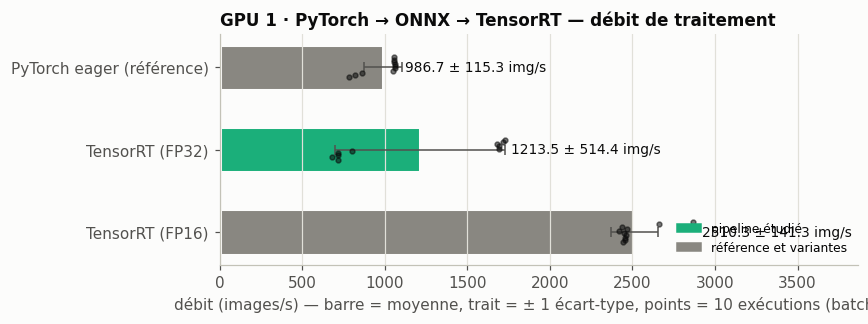

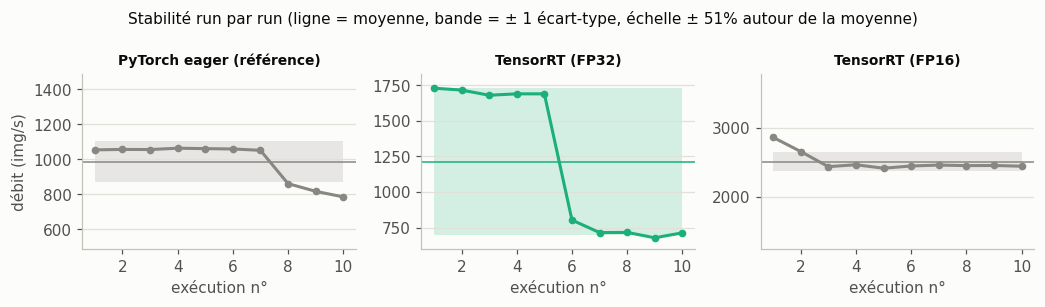

Résultats enregistrés : results/gpu1_tensorrt.json et results/gpu1_tensorrt_logits.npz


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
results_df = results_table()
display(results_df)
plot_local_results()
save_results()

# Archive à télécharger (Colab) : à décompresser à la racine du dépôt (dossiers results/ et figures/)
import shutil, zipfile
archive = f"{PIPELINE_ID}_sorties.zip"
with zipfile.ZipFile(archive, "w") as z:
    for folder in (RESULTS_DIR, FIGURES_DIR):
        for path in glob.glob(f"{folder}/{PIPELINE_ID}*"):
            z.write(path)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Hors Colab : archive créée ->", archive)

## Analyse (à compléter à partir de vos résultats)

- **Gain du pipeline** : accélération de TensorRT FP32 puis FP16 par rapport à PyTorch eager sur le même GPU. Quelle part vient de la fusion / sélection de tactiques (FP32) et quelle part de la demi-précision (FP16) ?
- **Fusion** : nombre de nœuds ONNX vs couches du moteur ; exemples de couches fusionnées (`example_layers`).
- **Qualité** : Top-1 et accord avec la référence en FP16 ; l'écart des logits augmente-t-il nettement par rapport au FP32 sans changer les prédictions ?
- **Énergie** : puissance moyenne et énergie par image (NVML) ; une variante plus rapide consomme-t-elle plus de watts mais moins de joules par image ?
- **Coût de préparation** : durée de construction des moteurs vs gain par image ; le moteur n'est valable que pour ce GPU et cette forme d'entrée.
- **Stabilité** : CV du débit ; effets de la fréquence du GPU (*boost*), de la température ou du partage de la machine Colab.